In [25]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


In [26]:
def apply_gaussian_filter(image, sigma):

    image = np.float32(image)

    frequency_domain = cv2.dft(image, flags=cv2.DFT_COMPLEX_OUTPUT)

    shifted_frequency_domain = np.fft.fftshift(frequency_domain, axes=(0, 1))

    rows, cols = image.shape
    crow, ccol = rows // 2, cols // 2

    mask = np.zeros((rows, cols), np.float32)

    for i in range(rows):
        for j in range(cols):
            mask[i, j] = np.exp(
                -((i - crow) ** 2 + (j - ccol) ** 2) / (2 * sigma ** 2)
            )

    # Apply Gaussian filter
    filtered_frequency_domain = shifted_frequency_domain * mask[:, :, np.newaxis]

    shifted_filtered_frequency_domain = np.fft.ifftshift(
        filtered_frequency_domain, axes=(0, 1)
    )

    filtered_image = cv2.idft(
        shifted_filtered_frequency_domain,
        flags=cv2.DFT_SCALE | cv2.DFT_REAL_OUTPUT
    )
    filtered_image = np.uint8(np.clip(filtered_image, 0, 255))

    return filtered_image

In [27]:
def apply_sharpening_filter(image, strength):

    image = np.float32(image)
    frequency_domain = cv2.dft(image, flags=cv2.DFT_COMPLEX_OUTPUT)

    shifted_frequency_domain = np.fft.fftshift(frequency_domain, axes=(0, 1))

    rows, cols = image.shape
    crow, ccol = rows // 2, cols // 2

    mask = np.zeros((rows, cols), np.float32)

    sigma = 20

    for i in range(rows):
        for j in range(cols):
            gaussian_mask = np.exp(
                -((i - crow) ** 2 + (j - ccol) ** 2) / (2 * sigma ** 2)
            )

            # High-boost filter
            mask[i, j] = 1 + strength * (1 - gaussian_mask)

    # Apply high-boost filter
    filtered_frequency_domain = shifted_frequency_domain * mask[:, :, np.newaxis]

    shifted_filtered_frequency_domain = np.fft.ifftshift(
        filtered_frequency_domain, axes=(0, 1)
    )

    filtered_image = cv2.idft(
        shifted_filtered_frequency_domain,
        flags=cv2.DFT_SCALE | cv2.DFT_REAL_OUTPUT
    )

    filtered_image = np.uint8(np.clip(filtered_image, 0, 255))

    return filtered_image

In [28]:
def extract_boundaries(image):

    boundary_image = cv2.Canny(image, 50, 150)

    return boundary_image

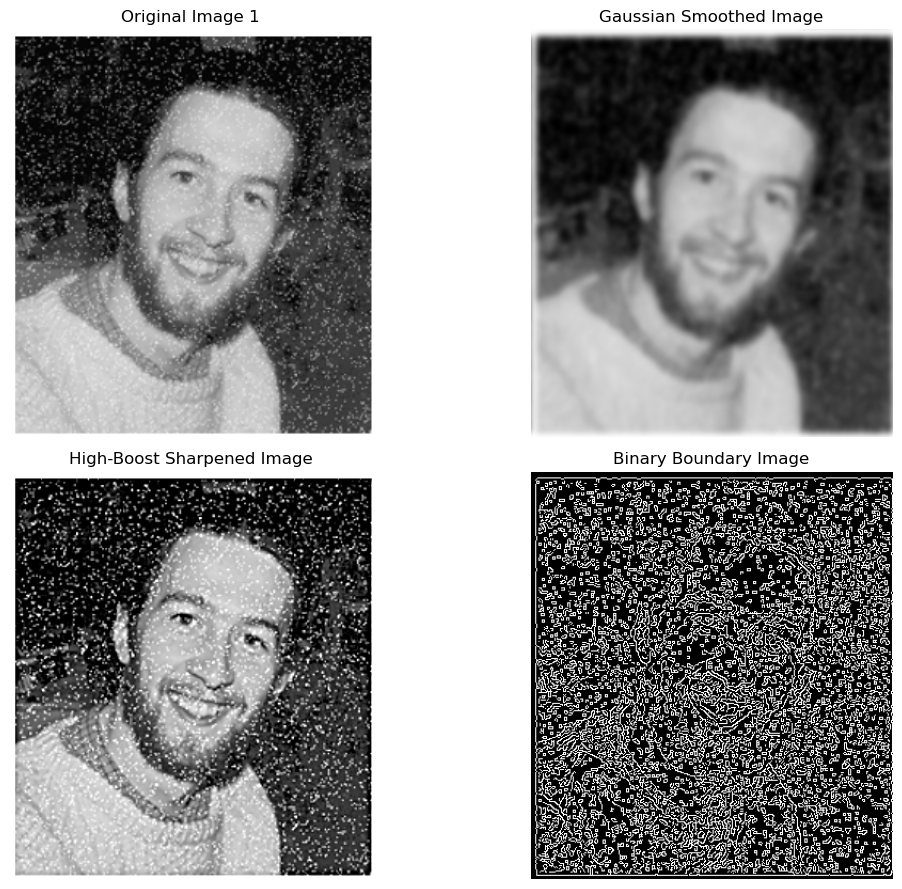

Image 1 processing completed successfully.
Smoothed image saved.
Sharpened image saved.
Boundary image saved.


In [29]:
# Load Image 1
image1 = cv2.imread("IMAGE1.png", 0)

if image1 is None:
    raise FileNotFoundError("Image 1 not found. Check the image path.")

# Apply Gaussian smoothing
sigma = 20
smoothed_image = apply_gaussian_filter(image1, sigma)

# Apply High-Boost sharpening
strength = 1.5
sharpened_image = apply_sharpening_filter(image1, strength)

# Extract boundaries from sharpened image
boundary_image = extract_boundaries(sharpened_image)

plt.figure(figsize=(12, 9))

plt.subplot(2, 2, 1)
plt.imshow(image1, cmap='gray')
plt.title("Original Image 1")
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(smoothed_image, cmap='gray')
plt.title("Gaussian Smoothed Image")
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(sharpened_image, cmap='gray')
plt.title("High-Boost Sharpened Image")
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(boundary_image, cmap='gray')
plt.title("Binary Boundary Image")
plt.axis('off')

plt.tight_layout()
plt.show()

cv2.imwrite('Image1_Smoothed.png', smoothed_image)
cv2.imwrite('Image1_Sharpened.png', sharpened_image)
cv2.imwrite('Image1_Boundary.png', boundary_image)

print("Image 1 processing completed successfully.")
print("Smoothed image saved.")
print("Sharpened image saved.")
print("Boundary image saved.")


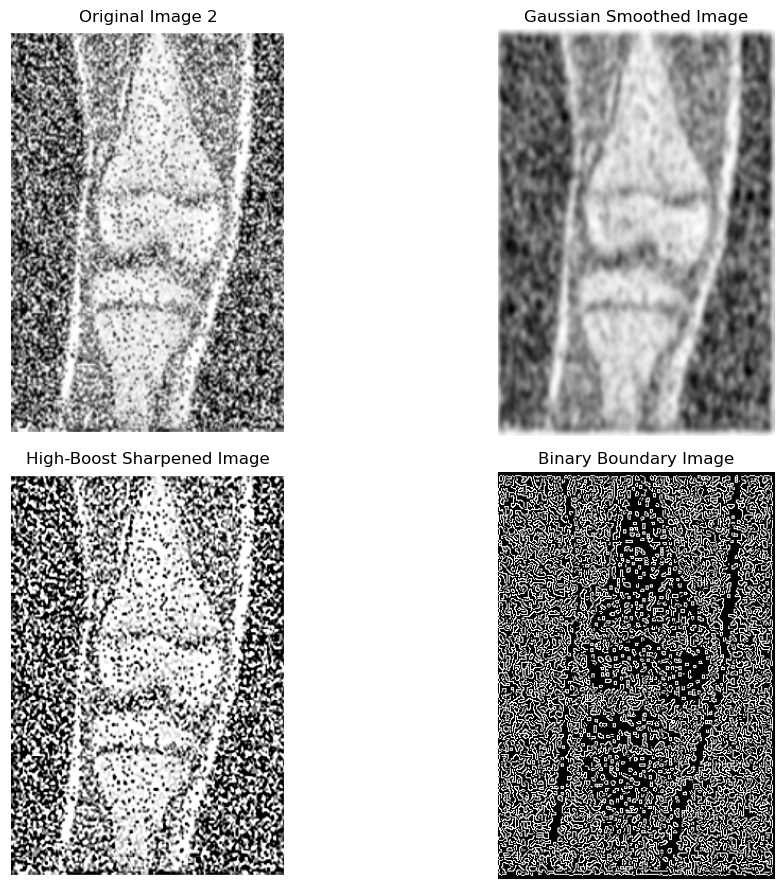

Image 2 processing completed successfully.
Smoothed image saved.
Sharpened image saved.
Boundary image saved.


In [30]:
# Load Image 2
image2 = cv2.imread("IMAGE2.png", 0)

if image2 is None:
    raise FileNotFoundError("Image 2 not found. Check the image path.")

# Apply Gaussian smoothing
sigma = 20
smoothed_image2 = apply_gaussian_filter(image2, sigma)

# Apply High-Boost sharpening
strength = 1.5
sharpened_image2 = apply_sharpening_filter(image2, strength)

# Extract boundaries from sharpened image
boundary_image2 = extract_boundaries(sharpened_image2)

plt.figure(figsize=(12, 9))

plt.subplot(2, 2, 1)
plt.imshow(image2, cmap='gray')
plt.title("Original Image 2")
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(smoothed_image2, cmap='gray')
plt.title("Gaussian Smoothed Image")
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(sharpened_image2, cmap='gray')
plt.title("High-Boost Sharpened Image")
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(boundary_image2, cmap='gray')
plt.title("Binary Boundary Image")
plt.axis('off')

plt.tight_layout()
plt.show()

cv2.imwrite('Image2_Smoothed.png', smoothed_image2)
cv2.imwrite('Image2_Sharpened.png', sharpened_image2)
cv2.imwrite('Image2_Boundary.png', boundary_image2)

print("Image 2 processing completed successfully.")
print("Smoothed image saved.")
print("Sharpened image saved.")
print("Boundary image saved.")

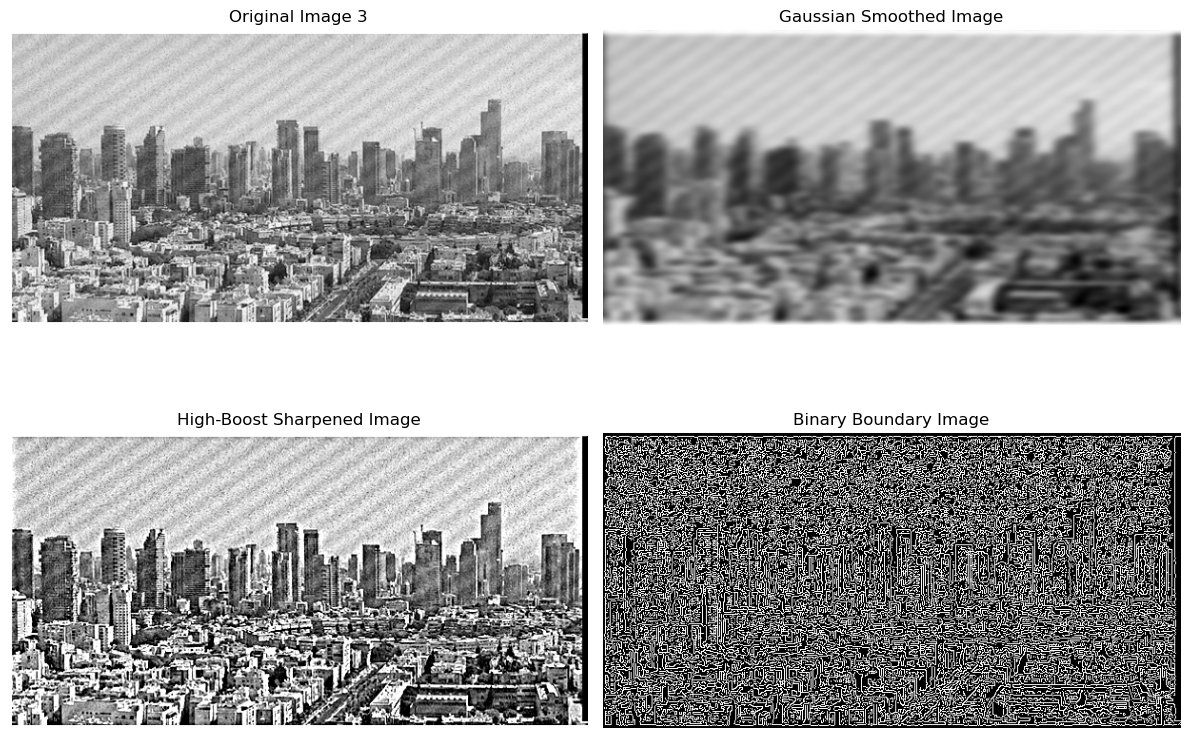

Image 3 processing completed successfully.
Smoothed image saved.
Sharpened image saved.
Boundary image saved.


In [31]:
# Load Image 3
image3 = cv2.imread("IMAGE3.png", 0)

if image3 is None:
    raise FileNotFoundError("Image 3 not found. Check the image path.")

# Apply Gaussian smoothing
sigma = 20
smoothed_image3 = apply_gaussian_filter(image3, sigma)

# Apply High-Boost sharpening
strength = 1.5
sharpened_image3 = apply_sharpening_filter(image3, strength)

# Extract boundaries from sharpened image
boundary_image3 = extract_boundaries(sharpened_image3)

plt.figure(figsize=(12, 9))

plt.subplot(2, 2, 1)
plt.imshow(image3, cmap='gray')
plt.title("Original Image 3")
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(smoothed_image3, cmap='gray')
plt.title("Gaussian Smoothed Image")
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(sharpened_image3, cmap='gray')
plt.title("High-Boost Sharpened Image")
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(boundary_image3, cmap='gray')
plt.title("Binary Boundary Image")
plt.axis('off')

plt.tight_layout()
plt.show()

cv2.imwrite('Image3_Smoothed.png', smoothed_image3)
cv2.imwrite('Image3_Sharpened.png', sharpened_image3)
cv2.imwrite('Image3_Boundary.png', boundary_image3)

print("Image 3 processing completed successfully.")
print("Smoothed image saved.")
print("Sharpened image saved.")
print("Boundary image saved.")

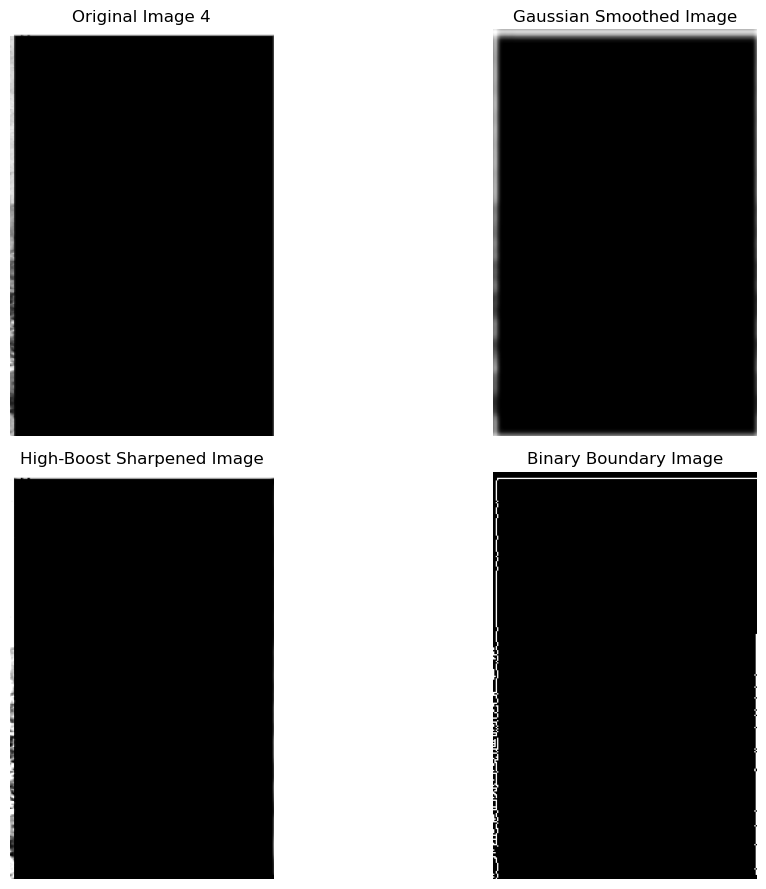

Image 4 processing completed successfully.
Smoothed image saved.
Sharpened image saved.
Boundary image saved.


In [32]:
# Load Image 4
image4 = cv2.imread("IMAGE4.png", 0)

if image4 is None:
    raise FileNotFoundError("Image 4 not found. Check the image path.")

# Apply Gaussian smoothing
sigma = 20
smoothed_image4 = apply_gaussian_filter(image4, sigma)

# Apply High-Boost sharpening
strength = 1.5
sharpened_image4 = apply_sharpening_filter(image4, strength)

# Extract boundaries from sharpened image
boundary_image4 = extract_boundaries(sharpened_image4)

plt.figure(figsize=(12, 9))

plt.subplot(2, 2, 1)
plt.imshow(image4, cmap='gray')
plt.title("Original Image 4")
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(smoothed_image4, cmap='gray')
plt.title("Gaussian Smoothed Image")
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(sharpened_image4, cmap='gray')
plt.title("High-Boost Sharpened Image")
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(boundary_image4, cmap='gray')
plt.title("Binary Boundary Image")
plt.axis('off')

plt.tight_layout()
plt.show()

cv2.imwrite('Image4_Smoothed.png', smoothed_image4)
cv2.imwrite('Image4_Sharpened.png', sharpened_image4)
cv2.imwrite('Image4_Boundary.png', boundary_image4)

print("Image 4 processing completed successfully.")
print("Smoothed image saved.")
print("Sharpened image saved.")
print("Boundary image saved.")

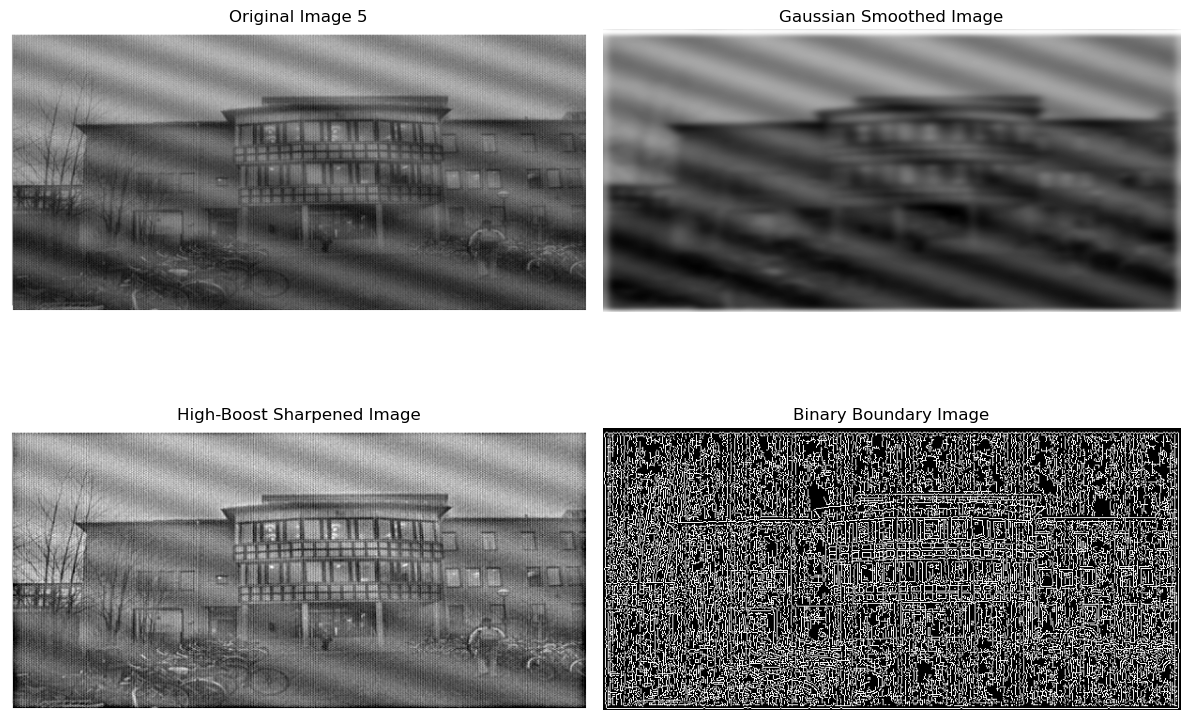

Image 5 processing completed successfully.
Smoothed image saved.
Sharpened image saved.
Boundary image saved.


In [33]:
# Load Image 5
image5 = cv2.imread("IMAGE5.png", 0)

if image5 is None:
    raise FileNotFoundError("Image 5 not found. Check the image path.")

# Apply Gaussian smoothing
sigma = 20
smoothed_image5 = apply_gaussian_filter(image5, sigma)

# Apply High-Boost sharpening
strength = 1.5
sharpened_image5 = apply_sharpening_filter(image5, strength)

# Extract boundaries from sharpened image
boundary_image5 = extract_boundaries(sharpened_image5)

plt.figure(figsize=(12, 9))

plt.subplot(2, 2, 1)
plt.imshow(image5, cmap='gray')
plt.title("Original Image 5")
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(smoothed_image5, cmap='gray')
plt.title("Gaussian Smoothed Image")
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(sharpened_image5, cmap='gray')
plt.title("High-Boost Sharpened Image")
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(boundary_image5, cmap='gray')
plt.title("Binary Boundary Image")
plt.axis('off')

plt.tight_layout()
plt.show()

cv2.imwrite('Image5_Smoothed.png', smoothed_image5)
cv2.imwrite('Image5_Sharpened.png', sharpened_image5)
cv2.imwrite('Image5_Boundary.png', boundary_image5)

print("Image 5 processing completed successfully.")
print("Smoothed image saved.")
print("Sharpened image saved.")
print("Boundary image saved.")

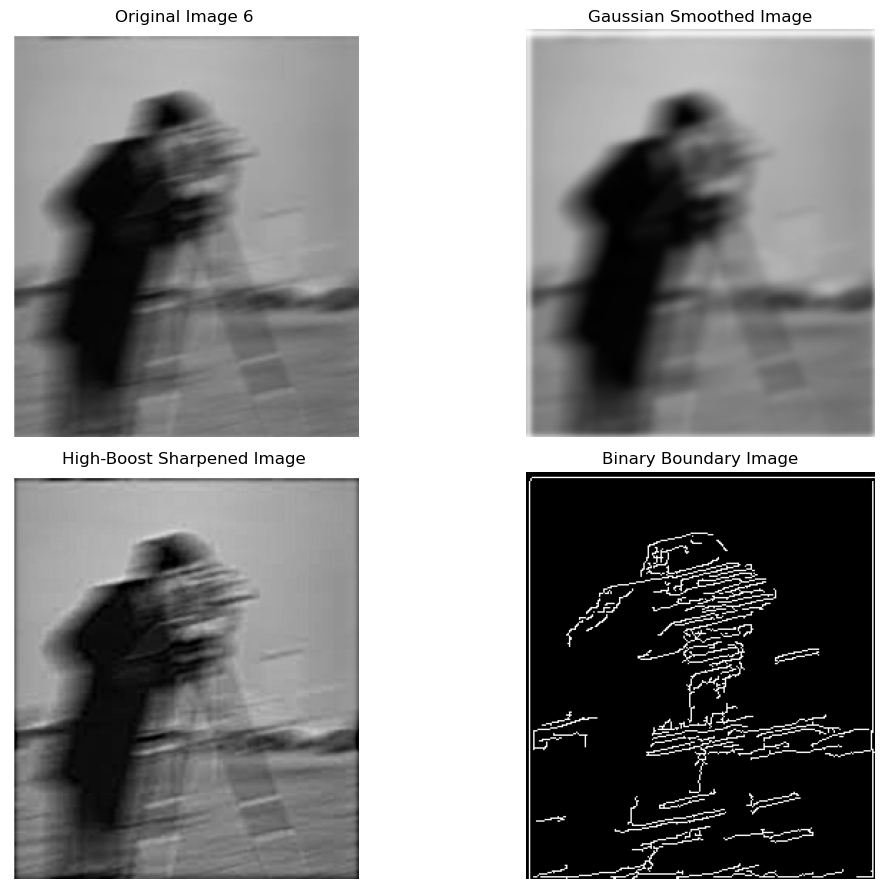

Image 6 processing completed successfully.
Smoothed image saved.
Sharpened image saved.
Boundary image saved.


In [34]:
# Load Image 6
image6 = cv2.imread("IMAGE6.png", 0)

if image6 is None:
    raise FileNotFoundError("Image 6 not found. Check the image path.")

# Apply Gaussian smoothing
sigma = 20
smoothed_image6 = apply_gaussian_filter(image6, sigma)

# Apply High-Boost sharpening
strength = 1.5
sharpened_image6 = apply_sharpening_filter(image6, strength)

# Extract boundaries from sharpened image
boundary_image6 = extract_boundaries(sharpened_image6)

plt.figure(figsize=(12, 9))

plt.subplot(2, 2, 1)
plt.imshow(image6, cmap='gray')
plt.title("Original Image 6")
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(smoothed_image6, cmap='gray')
plt.title("Gaussian Smoothed Image")
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(sharpened_image6, cmap='gray')
plt.title("High-Boost Sharpened Image")
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(boundary_image6, cmap='gray')
plt.title("Binary Boundary Image")
plt.axis('off')

plt.tight_layout()
plt.show()

cv2.imwrite('Image6_Smoothed.png', smoothed_image6)
cv2.imwrite('Image6_Sharpened.png', sharpened_image6)
cv2.imwrite('Image6_Boundary.png', boundary_image6)

print("Image 6 processing completed successfully.")
print("Smoothed image saved.")
print("Sharpened image saved.")
print("Boundary image saved.")